This notebook combines fixed-order and randomized barrier experiments at base-model level for barrier selection:

- **Canonical labels identify barriers** in every condition. Fixed legacy IDs represent positions; randomized IDs represent canonical barriers.

- **Random_seed42 has no single fixed order.** Actual positions are validated against each successful iteration's order log.

- Shares are percentages of all selections and sum to 100% per model/condition. The randomized position panel pools the actual selected positions across iterations.

- Seeded comparisons use Baseline_seed42. Baseline_seed42 itself is compared with the original Baseline.

- Matching corrections and parser policy changes are audited, not treated as data corruption. 

- Unnumbered formatting and acceptance rules also differ from legacy conditions. Results are descriptive.


In [8]:
#Cell 1 — configuration and canonical barrier IDs
from pathlib import Path
from collections import Counter
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path("/home/ngirwa/TiiS/second-publication/variability-tests/variability-barrier-list")
EXPORT_DIR = ROOT / "analysis-results"

MODELS = {
    "phi4": "Phi-4",
    "gemma3": "Gemma3:12B",
    "llama": "Llama-Pro",
    "mistral": "Mistral",
}

ROLES = {"generalist", "normative", "subject-matter"}
EXPECTED_ITERATIONS = 50

# Canonical IDs follow the original baseline order.
BARRIERS = {
    1: "power losses, quality and safety issues",
    2: "reduced reliability in DC devices",
    3: "lack of use-cases in which DC is advantageous",
    4: "uncertain utility interaction (net metering, utility ownership, and agreed standards)",
    5: "lack of pilot projects",
    6: "public perception of DC and readiness to 'champion' installations from DC projects",
    7: "incompatibility of DC systems components",
    8: "misconception and lack of knowledge leads to lengthy/expensive design and permit process",
    9: "lack of enough trained personnel in DC systems",
    10: "uncertain regulatory roadmap",
    11: "high costs of DC solutions",
}

LABEL_TO_ID = {label: key for key, label in BARRIERS.items()}

FILES = {
    "Baseline": (
        ROOT / "baseline-run"
        / "zeroshotBarrierSelectResponses.csv"
    ),
    "Baseline_seed42": (
        ROOT / "outputs/baseline-seed42"
        / "zeroshotBarrierSelectResponses_seed42.csv"
    ),
    "Run1_seed42": (
        ROOT / "outputs/run1-seed42"
        / "zeroshotBarrierSelectResponses_seed42_run1.csv"
    ),
    **{
        f"Run{i}": (
            ROOT / "outputs" / f"run{i}"
            / f"zeroshotBarrierSelectResponses_run{i}.csv"
        )
        for i in range(1, 4)
    },
    "Random_seed42": (
        ROOT / "outputs/randOrder-seed42"
        / "zeroshotBarrierSelectResponses_seed42_randOrder.csv"
    ),
}

CONDITIONS = list(FILES)

CONDITION_LABELS = {
    "Baseline": "Baseline",
    "Baseline_seed42": "Baseline (seed 42)",
    "Run1_seed42": "Run1 (seed 42)",
    "Run1": "Run1",
    "Run2": "Run2",
    "Run3": "Run3",
    "Random_seed42": "Random (seed 42)",
}

# Random_seed42 is intentionally absent: its order changes by iteration.
FIXED_ORDERS = {
    "Baseline": list(range(1, 12)),
    "Baseline_seed42": list(range(1, 12)),
    "Run1_seed42": [3, 4, 5, 6, 7, 8, 9, 10, 11, 1, 2],
    "Run1": [3, 4, 5, 6, 7, 8, 9, 10, 11, 1, 2],
    "Run2": [5, 6, 7, 8, 9, 10, 11, 1, 2, 3, 4],
    "Run3": [7, 8, 9, 10, 11, 1, 2, 3, 4, 5, 6],
}

In [9]:
#Cell 2 — load data and perform essential checks
frames = []

required_columns = {
    "base_model", "model", "iteration", "official_label"
}

for condition, path in FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"{condition}: {path}")

    frame = pd.read_csv(
        path,
        dtype=str,
        keep_default_na=False,
        encoding="utf-8-sig",
    )

    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(
            f"{condition}: missing columns {sorted(missing)}"
        )

    unknown_labels = sorted(
        set(frame["official_label"]) - set(LABEL_TO_ID)
    )
    if unknown_labels:
        raise ValueError(
            f"{condition}: unknown official labels: {unknown_labels}"
        )

    frame["condition"] = condition
    frame["role"] = frame["model"]
    frame["canonical_barrier_id"] = (
        frame["official_label"].map(LABEL_TO_ID)
    )

    if not frame["base_model"].isin(MODELS).all():
        raise ValueError(f"{condition}: unexpected model names.")

    if not frame["role"].isin(ROLES).all():
        raise ValueError(f"{condition}: unexpected variant roles.")

    iteration = pd.to_numeric(
        frame["iteration"], errors="coerce"
    )
    if iteration.isna().any() or iteration.mod(1).ne(0).any():
        raise ValueError(f"{condition}: invalid iteration values.")

    frame["iteration"] = iteration.astype(int)

    response_keys = ["base_model", "role", "iteration"]

    if frame.duplicated(
        response_keys + ["canonical_barrier_id"]
    ).any():
        raise ValueError(
            f"{condition}: duplicate barrier within a response."
        )

    response_sizes = frame.groupby(response_keys).size()
    if not response_sizes.eq(5).all():
        raise ValueError(
            f"{condition}: every response must contain five barriers."
        )

    expected_iterations = set(range(EXPECTED_ITERATIONS))

    for model in MODELS:
        for role in ROLES:
            subset = frame[
                (frame["base_model"] == model)
                & (frame["role"] == role)
            ]

            if set(subset["iteration"]) != expected_iterations:
                raise ValueError(
                    f"{condition}: incomplete iterations for "
                    f"{model}, {role}."
                )

    frames.append(frame)

data = pd.concat(frames, ignore_index=True)

print(
    f"Validated {len(CONDITIONS)} conditions: "
    "50 responses per variant, "
    "150 responses and 750 selections per model per condition."
)

Validated 7 conditions: 50 responses per variant, 150 responses and 750 selections per model per condition.


In [10]:
#Cell 3 — summarize actual randomized orders
random_data = data[
    data["condition"] == "Random_seed42"
].copy()

required_random_columns = {"attempt_id", "displayed_position"}
missing = required_random_columns - set(random_data.columns)

if missing:
    raise ValueError(
        f"Randomized CSV missing columns: {sorted(missing)}"
    )

position_values = pd.to_numeric(
    random_data["displayed_position"], errors="coerce"
)

if (
    position_values.isna().any()
    or position_values.mod(1).ne(0).any()
    or not position_values.between(1, 11).all()
):
    raise ValueError("Invalid randomized presentation positions.")

random_data["displayed_position"] = position_values.astype(int)

order_log_dir = (
    FILES["Random_seed42"].parent
    / "zeroshotBarrierSelectOrderLogs"
)

random_orders = []

for iteration, batch in random_data.groupby(
    "iteration", sort=True
):
    attempt_ids = batch["attempt_id"].unique()

    if len(attempt_ids) != 1:
        raise ValueError(
            f"Iteration {iteration}: variants do not share one attempt."
        )

    attempt_id = attempt_ids[0]
    log_path = order_log_dir / f"{attempt_id}.json"

    if not log_path.exists():
        raise FileNotFoundError(log_path)

    record = json.loads(log_path.read_text(encoding="utf-8"))

    if (
        record.get("status") != "success"
        or record.get("iteration") != int(iteration)
        or record.get("attempt_id") != attempt_id
    ):
        raise ValueError(
            f"Iteration {iteration}: incompatible order log."
        )

    items = record["order"]
    order = tuple(item["barrier_id"] for item in items)

    if len(order) != 11 or set(order) != set(BARRIERS):
        raise ValueError(
            f"Iteration {iteration}: invalid barrier permutation."
        )

    if [
        item["displayed_position"] for item in items
    ] != list(range(1, 12)):
        raise ValueError(
            f"Iteration {iteration}: invalid recorded positions."
        )

    for item in items:
        if item["official_label"] != BARRIERS[item["barrier_id"]]:
            raise ValueError(
                f"Iteration {iteration}: order-log label mismatch."
            )

    expected_positions = {
        barrier_id: position
        for position, barrier_id in enumerate(order, start=1)
    }

    if not batch["canonical_barrier_id"].map(
        expected_positions
    ).eq(batch["displayed_position"]).all():
        raise ValueError(
            f"Iteration {iteration}: CSV positions disagree with log."
        )

    random_orders.append(order)

order_counts = Counter(random_orders)

n_random_iterations = len(random_orders)
n_unique_orders = len(order_counts)
n_repeat_occurrences = n_random_iterations - n_unique_orders

random_order_summary = (
    f"Fisher-Yates; {n_unique_orders} unique orders among "
    f"{n_random_iterations} successful iterations; "
    f"{n_repeat_occurrences} repeat occurrences"
)

print(random_order_summary)

Fisher-Yates; 50 unique orders among 50 successful iterations; 0 repeat occurrences


In [11]:
#Cell 4 — export the two LaTeX tables
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

barrier_dictionary = pd.DataFrame([
    {
        "Barrier ID": f"B{barrier_id}",
        "Barrier label": label,
    }
    for barrier_id, label in BARRIERS.items()
])

presentation_rows = []

for condition in CONDITIONS:
    if condition == "Random_seed42":
        description = random_order_summary
    else:
        description = ", ".join(
            f"B{barrier_id}"
            for barrier_id in FIXED_ORDERS[condition]
        )

    presentation_rows.append({
        "Condition": CONDITION_LABELS[condition],
        "Presentation order or method": description,
    })

presentation_table = pd.DataFrame(presentation_rows)


def latex_escape(value):
    replacements = {
        "\\": r"\textbackslash{}",
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }
    return "".join(
        replacements.get(character, character)
        for character in str(value)
    )


def write_latex_table(
    frame, path, caption, label, column_format
):
    lines = [
        r"\begin{table}[htbp]",
        r"\centering",
        r"\small",
        r"\caption{" + latex_escape(caption) + "}",
        r"\label{" + label + "}",
        r"\begin{tabular}{" + column_format + "}",
        r"\hline",
        " & ".join(
            latex_escape(column) for column in frame.columns
        ) + r" \\",
        r"\hline",
    ]

    for row in frame.itertuples(index=False, name=None):
        lines.append(
            " & ".join(latex_escape(value) for value in row)
            + r" \\"
        )

    lines.extend([
        r"\hline",
        r"\end{tabular}",
        r"\end{table}",
    ])

    path.write_text(
        "\n".join(lines) + "\n",
        encoding="utf-8",
    )


write_latex_table(
    barrier_dictionary,
    EXPORT_DIR / "barrier_dictionary.tex",
    caption="Canonical barrier identifiers in baseline order.",
    label="tab:barrier-dictionary",
    column_format=r"lp{0.80\linewidth}",
)

write_latex_table(
    presentation_table,
    EXPORT_DIR / "barrier_presentation_orders.tex",
    caption=(
        "Barrier presentation across experimental conditions. "
        "Randomized-order counts exclude failed retries."
    ),
    label="tab:barrier-presentation-orders",
    column_format=r"lp{0.62\linewidth}",
)

display(barrier_dictionary)
display(presentation_table)

print(f"LaTeX tables saved in: {EXPORT_DIR}")

,Barrier ID,Barrier label
0,B1,"power losses, quality and safety issues"
1,B2,reduced reliability in DC devices
2,B3,lack of use-cases in which DC is advantageous
3,B4,"uncertain utility interaction (net metering, u..."
4,B5,lack of pilot projects
5,B6,public perception of DC and readiness to 'cham...
6,B7,incompatibility of DC systems components
7,B8,misconception and lack of knowledge leads to l...
8,B9,lack of enough trained personnel in DC systems
9,B10,uncertain regulatory roadmap


,Condition,Presentation order or method
0,Baseline,"B1, B2, B3, B4, B5, B6, B7, B8, B9, B10, B11"
1,Baseline (seed 42),"B1, B2, B3, B4, B5, B6, B7, B8, B9, B10, B11"
2,Run1 (seed 42),"B3, B4, B5, B6, B7, B8, B9, B10, B11, B1, B2"
3,Run1,"B3, B4, B5, B6, B7, B8, B9, B10, B11, B1, B2"
4,Run2,"B5, B6, B7, B8, B9, B10, B11, B1, B2, B3, B4"
5,Run3,"B7, B8, B9, B10, B11, B1, B2, B3, B4, B5, B6"
6,Random (seed 42),Fisher-Yates; 50 unique orders among 50 succes...


LaTeX tables saved in: /home/ngirwa/TiiS/second-publication/variability-tests/variability-barrier-list/analysis-results


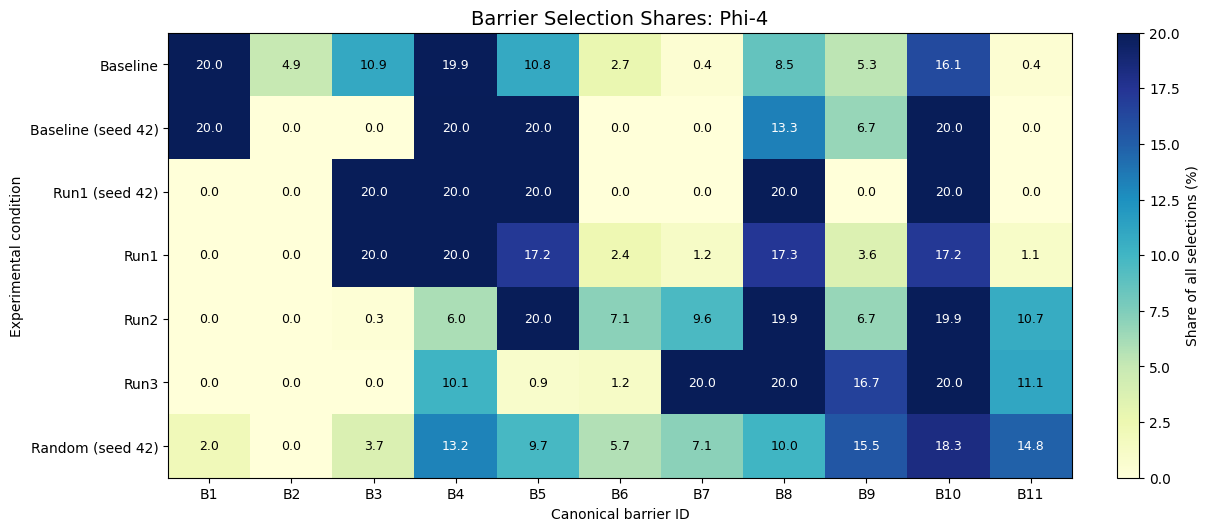

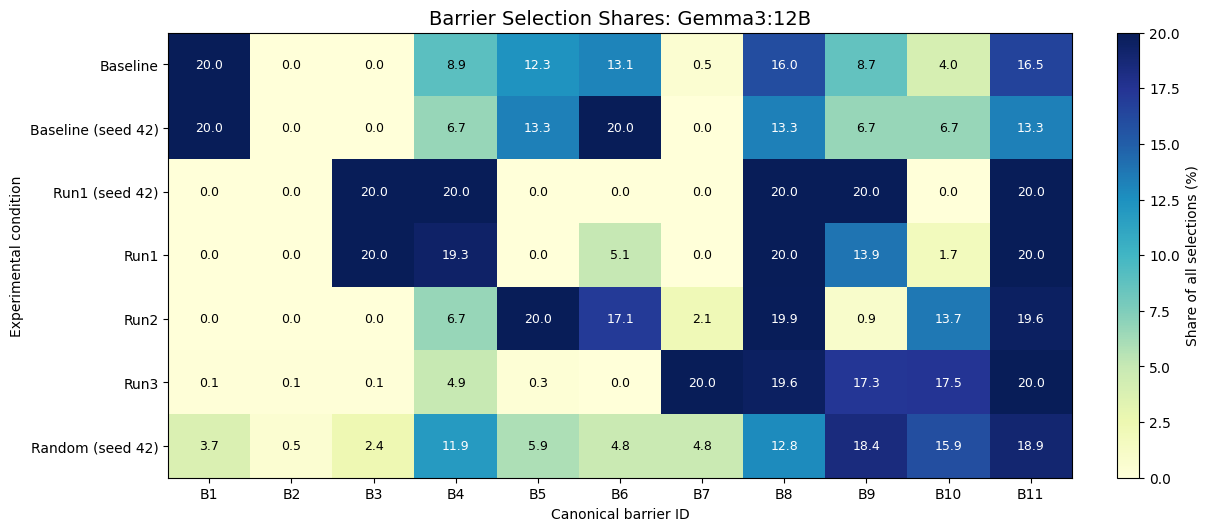

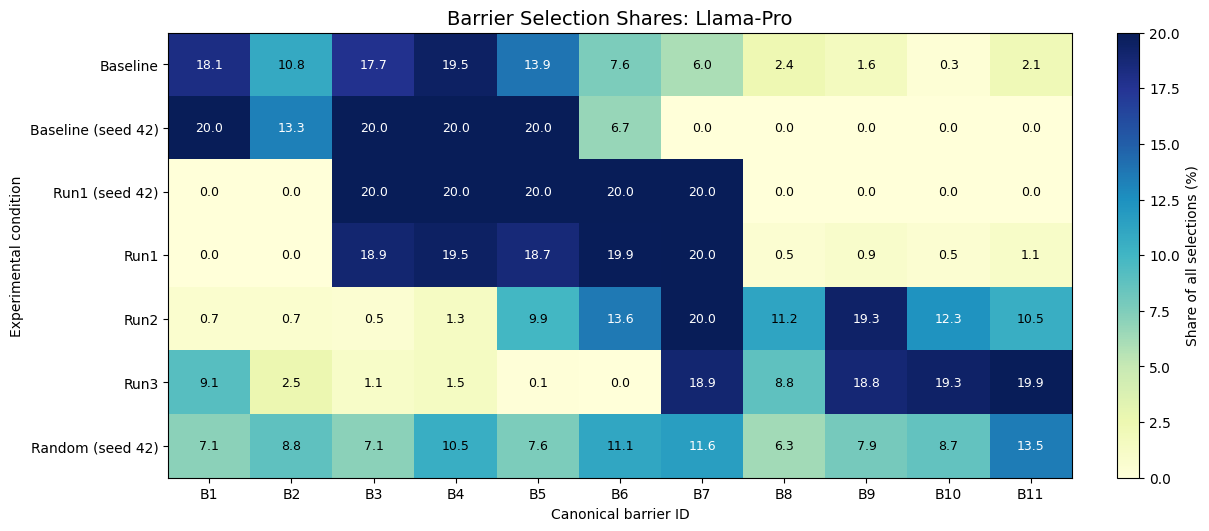

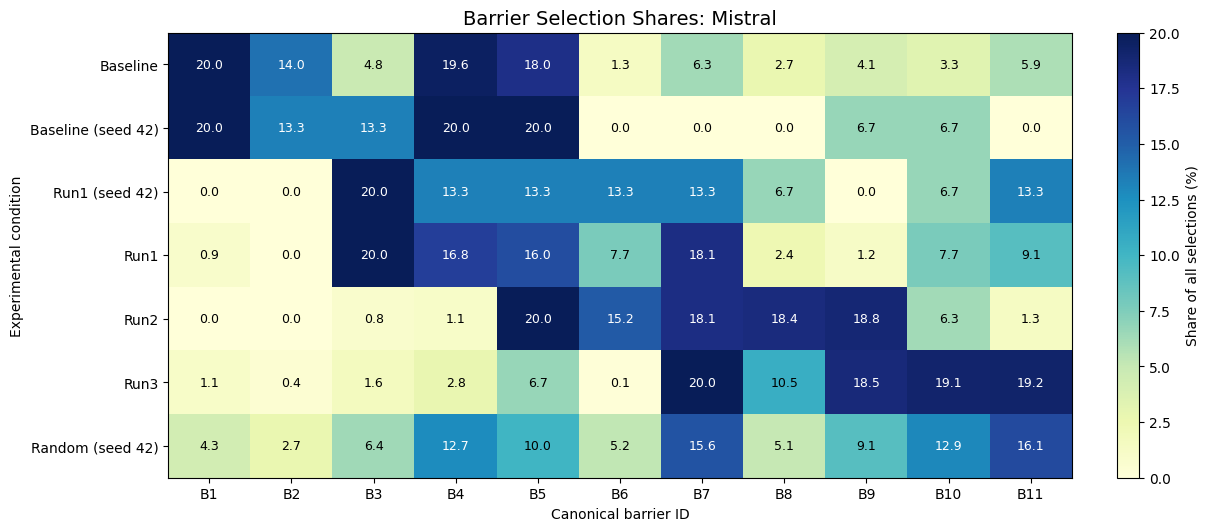

In [12]:
#Cell 5 — four model-level heatmaps
index = pd.MultiIndex.from_product(
    [list(MODELS), CONDITIONS, list(BARRIERS)],
    names=[
        "base_model", "condition", "canonical_barrier_id"
    ],
)

selection_counts = (
    data.groupby([
        "base_model", "condition", "canonical_barrier_id"
    ])
    .size()
    .reindex(index, fill_value=0)
    .rename("selection_count")
    .reset_index()
)

totals = (
    data.groupby(["base_model", "condition"])
    .size()
    .rename("total_selections")
    .reset_index()
)

selection_shares = selection_counts.merge(
    totals,
    on=["base_model", "condition"],
    validate="many_to_one",
)

selection_shares["share_pct"] = (
    selection_shares["selection_count"]
    / selection_shares["total_selections"]
    * 100
)

row_totals = selection_shares.groupby(
    ["base_model", "condition"]
)["share_pct"].sum()

assert np.allclose(row_totals.to_numpy(), 100)
assert selection_shares["share_pct"].le(20 + 1e-9).all()

# Set True if you also want PDF exports of the figures.
SAVE_FIGURES = True

for model, display_name in MODELS.items():
    matrix = (
        selection_shares[
            selection_shares["base_model"] == model
        ]
        .pivot(
            index="condition",
            columns="canonical_barrier_id",
            values="share_pct",
        )
        .reindex(
            index=CONDITIONS,
            columns=list(BARRIERS),
        )
    )

    fig, ax = plt.subplots(
        figsize=(12, 5.2),
        constrained_layout=True,
    )

    image = ax.imshow(
        matrix.to_numpy(),
        cmap="YlGnBu",
        vmin=0,
        vmax=20,
        aspect="auto",
        interpolation="nearest",
    )

    ax.set_xticks(range(len(BARRIERS)))
    ax.set_xticklabels([
        f"B{barrier_id}" for barrier_id in BARRIERS
    ])

    ax.set_yticks(range(len(CONDITIONS)))
    ax.set_yticklabels([
        CONDITION_LABELS[condition]
        for condition in CONDITIONS
    ])

    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix.iloc[row, column]
            rgba = image.cmap(image.norm(value))

            brightness = (
                0.299 * rgba[0]
                + 0.587 * rgba[1]
                + 0.114 * rgba[2]
            )

            ax.text(
                column,
                row,
                f"{value:.1f}",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if brightness < 0.5 else "black",
            )

    ax.set_title(
        f"Barrier Selection Shares: {display_name}",
        fontsize=14,
    )
    ax.set_xlabel("Canonical barrier ID")
    ax.set_ylabel("Experimental condition")

    fig.colorbar(
        image,
        ax=ax,
        label="Share of all selections (%)",
    )

    if SAVE_FIGURES:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf"):
            fig.savefig(
                EXPORT_DIR / f"{model}_barrier_selection_heatmap.{extension}",
                dpi=300,
                bbox_inches="tight",
            )

    plt.show()